# Climate Risk and Health Prediction

This notebook explains the fixed solution prepared for the Zindi challenge.
It predicts whether a recorded death belongs to the provided climate-sensitive category.

The solution combines Random Forest and HistGradientBoosting, with a small contribution
from a second pair of models that adds six months of rainfall.

Run the cells in order. Input files belong in `data/`; generated files go to ignored
folders. The original submission is only used for an optional reproduction comparison.
It is never an input to feature engineering, fitting or prediction.

[Competition](https://zindi.world/competitions/climate-risk-health-prediction-challenge)


## 1. Setup

Use the project virtual environment and install `requirements-notebook.txt`.
Run this notebook from the repository root or the `notebooks` folder.
There are no personal machine paths in the notebook.

The small helper below runs the same command-line scripts documented in the README,
using the notebook's Python interpreter. There is only one implementation of the model.


In [1]:
from pathlib import Path
import json
import subprocess
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = Path.cwd().resolve()
if not (ROOT / "src").is_dir():
    ROOT = ROOT.parent
if not (ROOT / "src").is_dir():
    raise FileNotFoundError("Open this notebook from the project root or notebooks folder.")
sys.path.insert(0, str(ROOT))
DATA = ROOT / "data"
OUTPUTS = ROOT / "outputs"
OUTPUTS.mkdir(exist_ok=True)
FIGURES = OUTPUTS / "figures"
FIGURES.mkdir(exist_ok=True)

from src.features import (
    AGE_BINS, AGE_LABELS, BASE_COLUMNS, CACHE_NAME, RAIN_COLUMN,
    base_features, build_matrices, load_rainfall_cache, load_rows, training_target,
)
from src.models import HGB_PARAMS, RF_PARAMS, WEIGHTS, software_versions
from src.predict import check_submission
from src.validate import geographic_groups

def run_module(name, *arguments):
    result = subprocess.run(
        [sys.executable, "-m", name, *arguments], cwd=ROOT,
        capture_output=True, text=True,
    )
    if result.returncode:
        raise RuntimeError(result.stdout + result.stderr)
    print(result.stdout.strip())

plt.rcParams.update({"figure.figsize": (10, 4), "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})
display(pd.Series(software_versions(), name="Version").to_frame())


,Version
numpy,2.3.5
pandas,3.0.1
scikit-learn,1.9.1
scipy,1.18.1
joblib,1.6.0
threadpoolctl,3.7.0


## 2. Read the data

There are 3,146 labelled records and 1,030 test records in the original challenge files.
The target is `is_climate_sensitive`. A value of 1 is the positive class.

The selected model uses age, gender, zone and date. Coordinates are used to look up
rainfall and build validation groups. IDs are used to align outputs.
The provided temperature, vegetation and terrain variables are not predictors in
this selected recipe.

The tables below contain aggregate summaries, not individual records.


In [2]:
train = load_rows(DATA / "Train.csv")
test = load_rows(DATA / "Test.csv")
sample = pd.read_csv(DATA / "SampleSubmission.csv")
y = training_target(train)
groups = geographic_groups(train)

overview = pd.DataFrame({
    "Dataset": ["Train", "Test"],
    "Rows": [len(train), len(test)],
    "Unique locations": [train.location.nunique(), test.location.nunique()],
    "First date": [train.deathdate.min().date(), test.deathdate.min().date()],
    "Last date": [train.deathdate.max().date(), test.deathdate.max().date()],
})
display(overview.set_index("Dataset"))
required = ["age", "gender", "zone", "deathdate", "latitude", "longitude", "location"]
display(pd.DataFrame({"Train missing": train[required].isna().sum(),
                      "Test missing": test[required].isna().sum()}))
print(f"Connected training geography groups: {len(np.unique(groups))}")
print(f"Positive training class: {y.mean():.1%}")


,Rows,Unique locations,First date,Last date
Dataset,,,,
Train,3146,39,2007-10-02,2022-12-13
Test,1030,11,2007-11-24,2022-05-17


,Train missing,Test missing
age,0,0
gender,0,0
zone,0,0
deathdate,0,0
latitude,0,0
longitude,0,0
location,0,0


Connected training geography groups: 38
Positive training class: 65.1%


## 3. Age and the target

Age is used both as a number and as a set of age-group indicators. The indicators
give the model explicit groups for infants, children and adults.

Compare the target rate with the number of records in each group. A rate from a
small group is less stable. These are associations in the supplied labels; they
do not establish that age or climate caused an outcome.


,records,positive_rate
age_group,,
Age 0,1112,0.788
Age 1,281,0.936
Ages 2-5,363,0.906
Ages 6-17,116,0.586
Ages 18-49,503,0.519
Ages 50-64,197,0.406
Age 65+,574,0.296


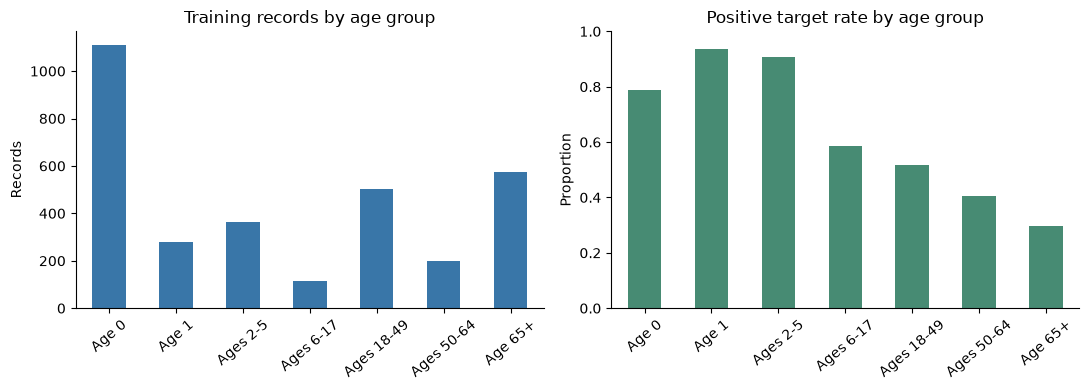

In [3]:
age_groups = pd.cut(train.age, AGE_BINS, labels=AGE_LABELS, include_lowest=True, right=True)
age_summary = train.assign(age_group=age_groups).groupby("age_group", observed=True).agg(
    records=("is_climate_sensitive", "size"),
    positive_rate=("is_climate_sensitive", "mean"),
)
display(age_summary.round(3))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
age_summary.records.plot.bar(ax=axes[0], color="#3976a8", rot=40)
axes[0].set(title="Training records by age group", xlabel="", ylabel="Records")
age_summary.positive_rate.plot.bar(ax=axes[1], color="#478b73", rot=40)
axes[1].set(title="Positive target rate by age group", xlabel="", ylabel="Proportion", ylim=(0, 1))
fig.tight_layout()
fig.savefig(FIGURES / "age_summary.png", dpi=140, bbox_inches="tight")
plt.show()


## 4. Dates and the period feature

The recipe includes a period indicator starting on 1 July 2017, plus its interactions
with each age group. This boundary came from earlier exploration of these training
labels. It is not proof of a documented change in the data source.

The plots show why dates deserved attention. Reusing this boundary across validation
folds preserves the submitted recipe, but does not undo the selection made during EDA.


,records,positive_rate
period,,
Before July 2017,2369,0.690
July 2017 onward,777,0.532


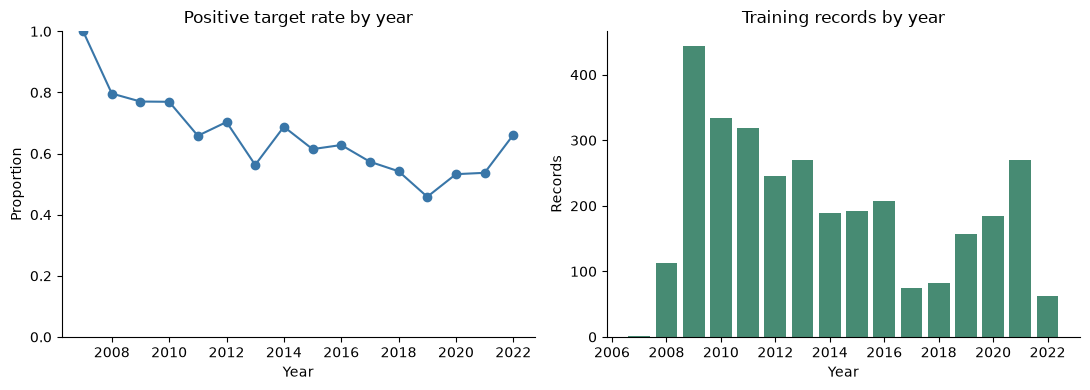

In [4]:
year_summary = train.assign(year=train.deathdate.dt.year).groupby("year").agg(
    records=("is_climate_sensitive", "size"),
    positive_rate=("is_climate_sensitive", "mean"),
)
period_summary = train.assign(
    period=np.where(train.deathdate >= "2017-07-01", "July 2017 onward", "Before July 2017")
).groupby("period").agg(records=("is_climate_sensitive", "size"),
                       positive_rate=("is_climate_sensitive", "mean"))
display(period_summary.round(3))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(year_summary.index, year_summary.positive_rate, marker="o", color="#3976a8")
axes[0].set(title="Positive target rate by year", xlabel="Year", ylabel="Proportion", ylim=(0, 1))
axes[1].bar(year_summary.index, year_summary.records, color="#478b73")
axes[1].set(title="Training records by year", xlabel="Year", ylabel="Records")
fig.tight_layout()
fig.savefig(FIGURES / "year_summary.png", dpi=140, bbox_inches="tight")
plt.show()


## 5. Rainfall preparation

The external source is CHIRPS **v3** monthly rainfall from the Climate Hazards Center.
Each supplied coordinate is matched to a raster cell. For each record, the model
uses the sum of six complete months ending before the record's month.

For a record dated 15 August 2020, the window is February through July 2020.
August and later rainfall are excluded. The amount is measured in millimetres.

The command reuses an existing cache. If samples are missing, it downloads the needed
rasters; a fresh download may take some time. No labels or IDs are sent to the provider.
CHIRPS is retrospective, so this is not a historical real-time forecasting backtest.

[Source](https://www.chc.ucsb.edu/data/chirps3) · [Dataset citation](https://doi.org/10.15780/G2JQ0P)


In [5]:
run_module("src.prepare_climate", "--data-dir", str(DATA))
cache = load_rainfall_cache(DATA / CACHE_NAME)
train_matrices = build_matrices(train, cache)
test_matrices = build_matrices(test, cache)
display(pd.DataFrame({
    "Train": train_matrices["rain6"][RAIN_COLUMN].describe(),
    "Test": test_matrices["rain6"][RAIN_COLUMN].describe(),
}).round(2))


Coordinates: 55. Monthly rasters to download: 0.
Rainfall features are ready. Training rebuilds them from this same cache.


,Train,Test
count,3146.00,1030.00
mean,769.50,771.06
std,160.57,230.56
min,455.94,329.78
25%,652.54,623.75
50%,748.35,726.38
75%,867.52,885.77
max,1468.14,1977.56


## 6. What enters each model

The baseline contains 23 numeric columns:

- Age: 1
- One-hot age groups: 7
- One-hot gender and zone: 4
- Year, sine/cosine month and the period indicator: 4
- Age-group × period interactions: 7

The rainfall branch contains those same columns plus the six-month total: 24 columns.
All one-hot levels are fixed. There is no target encoding, scaling or learned
imputation. Unexpected categories and missing required values raise an error.

The following two rows are **made-up examples**, including their rainfall values.
They show the model input without displaying real participant records.


In [6]:
examples = pd.DataFrame({
    "age": [0, 55], "gender": ["Female", "Male"],
    "zone": ["Rural", "Peri_urban"], "deathdate": ["2016-02-15", "2020-08-15"],
})
example_matrix = base_features(examples)
example_matrix[RAIN_COLUMN] = [250.0, 600.0]
example_matrix.index = ["Example 1", "Example 2"]
display(example_matrix.T.round(4))
display(pd.DataFrame({
    "Branch": ["Baseline", "Rainfall"],
    "Training matrix": [str(train_matrices["baseline"].shape), str(train_matrices["rain6"].shape)],
    "Test matrix": [str(test_matrices["baseline"].shape), str(test_matrices["rain6"].shape)],
}).set_index("Branch"))


,Example 1,Example 2
age,0.000,55.000
age_group_Age 0,1.000,0.000
age_group_Age 1,0.000,0.000
age_group_Age 65+,0.000,0.000
age_group_Ages 18-49,0.000,0.000
age_group_Ages 2-5,0.000,0.000
age_group_Ages 50-64,0.000,1.000
age_group_Ages 6-17,0.000,0.000
gender_Female,1.000,0.000
gender_Male,0.000,1.000


,Training matrix,Test matrix
Branch,,
Baseline,"(3146, 23)","(1030, 23)"
Rainfall,"(3146, 24)","(1030, 24)"


## 7. The four models

Each branch fits one Random Forest and one HistGradientBoosting model. Their settings
are identical across branches, but their feature matrices differ.

Random Forest averages many trees trained with bootstrap samples. HistGradientBoosting
builds trees in sequence. Minimum leaf sizes and the small boosting trees limit how
closely these models can fit small groups of training examples.

The original parameters are shown below. This notebook does not search for new ones.


In [7]:
display(pd.Series(RF_PARAMS, name="Random Forest").to_frame())
display(pd.Series(HGB_PARAMS, name="HistGradientBoosting").to_frame())
display(pd.Series(WEIGHTS, name="Fixed weight").to_frame())


,Random Forest
n_estimators,300
max_features,sqrt
min_samples_leaf,30
class_weight,None
random_state,42
n_jobs,4


,HistGradientBoosting
learning_rate,0.03
max_iter,100
max_leaf_nodes,7
min_samples_leaf,35
l2_regularization,1.0
early_stopping,False
random_state,42


,Fixed weight
rf,0.6
hgb,0.4
baseline,0.8
rain6,0.2


The probabilities are combined as follows:

```text
baseline = 0.60 × RF_base + 0.40 × HGB_base
rainfall = 0.60 × RF_rain + 0.40 × HGB_rain
final    = 0.80 × baseline + 0.20 × rainfall
```

This is weighted probability averaging. There is no stacking model or calibration step.

## 8. Geographic validation

Random row splits can place records from the same location in both training and
validation. Here, entire connected location groups are held out. Different names
sharing a coordinate are connected before assigning folds.

The fixed recipe is evaluated with five folds for each of four seeds:
17011, 29017, 51031 and 73013. Each row receives a prediction from a model that did
not train on its geographic group. All branches use the same splits.

The competition score is `0.60 × F1 + 0.40 × ROC-AUC`. F1 uses a fixed 0.5 threshold;
ROC-AUC uses the probabilities. We score each complete set of out-of-fold predictions,
then average the four assignment scores. We do not average the labels or tune thresholds.

These are the previously used assignments, not new untouched data. Running this cell
checks the cleaned implementation; it does not provide a new independent experiment.


In [8]:
run_module("src.validate", "--data-dir", str(DATA), "--output-dir", "outputs/validation")
scores = pd.read_csv(OUTPUTS / "validation" / "scores.csv")
summary = pd.read_csv(OUTPUTS / "validation" / "summary.csv")
names = {"baseline": "Baseline", "rain6": "Rainfall pair alone", "final": "80/20 final blend"}
display(scores.pivot(index="seed", columns="model", values="score").rename(columns=names).round(6))
display(summary.assign(model=summary.model.map(names)).set_index("model").round(6))
wide = scores.pivot(index="seed", columns="model", values="score")
print(f"Mean final-minus-baseline difference: {(wide['final'] - wide['baseline']).mean():+.6f}")


Seed 17011: fold 1/5 complete.
Seed 17011: fold 2/5 complete.
Seed 17011: fold 3/5 complete.
Seed 17011: fold 4/5 complete.
Seed 17011: fold 5/5 complete.
Seed 29017: fold 1/5 complete.
Seed 29017: fold 2/5 complete.
Seed 29017: fold 3/5 complete.
Seed 29017: fold 4/5 complete.
Seed 29017: fold 5/5 complete.
Seed 51031: fold 1/5 complete.
Seed 51031: fold 2/5 complete.
Seed 51031: fold 3/5 complete.
Seed 51031: fold 4/5 complete.
Seed 51031: fold 5/5 complete.
Seed 73013: fold 1/5 complete.
Seed 73013: fold 2/5 complete.
Seed 73013: fold 3/5 complete.
Seed 73013: fold 4/5 complete.
Seed 73013: fold 5/5 complete.
   model       f1      auc    score
baseline 0.818445 0.825980 0.821459
   final 0.818251 0.825969 0.821338
   rain6 0.817306 0.825590 0.820619
These assignments reuse the training labels; they are not an untouched test set.


model,Baseline,80/20 final blend,Rainfall pair alone
seed,,,
17011,0.821584,0.821236,0.820650
29017,0.820598,0.820138,0.819850
51031,0.820628,0.821008,0.820819
73013,0.823026,0.822971,0.821159


,f1,auc,score
model,,,
Baseline,0.818445,0.825980,0.821459
80/20 final blend,0.818251,0.825969,0.821338
Rainfall pair alone,0.817306,0.825590,0.820619


Mean final-minus-baseline difference: -0.000121


The original audit found mean scores of about 0.821459 for the baseline and 0.821338
for the final six-month blend. The rainfall blend did not consistently improve
geographic validation, even though its reported public score was higher.

## 9. Train on all rows and predict

Validation models are not used to generate this submission. The following commands
fit all four models on the complete training dataset, save them, then start a separate
process to load them and predict Test rows.

The prediction script checks feature order, dependency versions and the rainfall cache.
It aligns IDs with the sample submission and writes unmodified probabilities.


In [9]:
run_module("src.train", "--data-dir", str(DATA), "--model-dir", "models")
run_module("src.predict", "--data-dir", str(DATA), "--model-dir", "models",
           "--output", "outputs/submission.csv")

submission = pd.read_csv(OUTPUTS / "submission.csv", float_precision="round_trip")
check_submission(submission, sample)
manifest = json.loads((ROOT / "models" / "training_manifest.json").read_text())
display(pd.Series({
    "Training rows": manifest["training_rows"],
    "Prediction rows": len(submission),
    "Minimum probability": submission.TargetRAUC.min(),
    "Maximum probability": submission.TargetRAUC.max(),
    "Positive predictions": int(submission.TargetF1.sum()),
    "IDs match sample order": submission.ID.tolist() == sample.ID.tolist(),
    "Binary labels use 0.5": bool(np.array_equal(submission.TargetF1, (submission.TargetRAUC >= 0.5).astype(int))),
}, name="Submission checks").to_frame())


Trained all four models on 3146 rows.
Saved models\rf_hgb_chirps6.joblib


Saved 1030 predictions to outputs\submission.csv


,Submission checks
Training rows,3146
Prediction rows,1030
Minimum probability,0.221554
Maximum probability,0.956453
Positive predictions,719
IDs match sample order,True
Binary labels use 0.5,True


## 10. Optional comparison with the original submission

For this project's reproduction check, a local copy of the original six-month CSV is
stored as `data/reference_submission.csv`. It is ignored by Git and is never used
for training or model selection.

If that file is available, this cell checks ID alignment, probability differences,
binary labels, rainfall windows and the saved model recipe. Without it, the pipeline
still runs, but an exact comparison with the old artifact cannot be made.


In [10]:
reference = DATA / "reference_submission.csv"
if reference.exists():
    run_module("src.verify", "--data-dir", str(DATA), "--model-dir", "models",
               "--submission", "outputs/submission.csv", "--reference", str(reference),
               "--report", "outputs/reproduction_check.json")
    reproduction = json.loads((OUTPUTS / "reproduction_check.json").read_text())
    display(pd.Series(reproduction["checks"], name="Passed").to_frame())
else:
    print("No local reference CSV: original-submission comparison was not run.")


Checks passed: 18/18
Maximum probability difference: 4.44e-16
Binary prediction differences: 0
Report: outputs\reproduction_check.json


,Passed
submission_format_ids_order_and_threshold,True
probabilities_match_reference_within_1e_10,True
binary_predictions_match_reference,True
train_test_features_have_expected_order,True
features_do_not_use_labels_or_ids,True
rainfall_windows_end_before_events,True
independent_rainfall_reconstruction_matches,True
training_manifest_records_all_rows,True
training_input_hash_matches,True
rainfall_cache_hash_matches,True


## 11. Results and limits

Results reported for the competition account:

| Measure | Reported result |
| --- | ---: |
| Public score associated with this six-month CSV | 0.842894491 |
| Private score shown on the shared leaderboard | 0.821546589 |
| Private rank shown on the shared leaderboard | 109, provisional in that notice |

These are reported leaderboard results, not scores calculated from private labels
in this notebook. The challenge displays the best private score among the two selected
submissions; a per-submission private score is needed to independently attribute that
private result to a particular CSV. The displayed rank has not been refreshed here.

The code checks reduce specific leakage and reproducibility risks. They do not prove
zero overfitting: many earlier feature and model decisions reused these training labels,
and the period boundary was chosen during exploration.

Other model families and climate features were tested earlier. They are not included
in this fixed final pipeline. No external health or mortality sample is used here.

This work classifies historical records. It is not a clinical tool or evidence that
a particular weather exposure caused an individual death.
